<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_2_Disease_Detection/TeaLeafDiseaseDetectionSystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TeaLeafDiseaseDetectionSystem**

EDA


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


Mounted at /content/drive


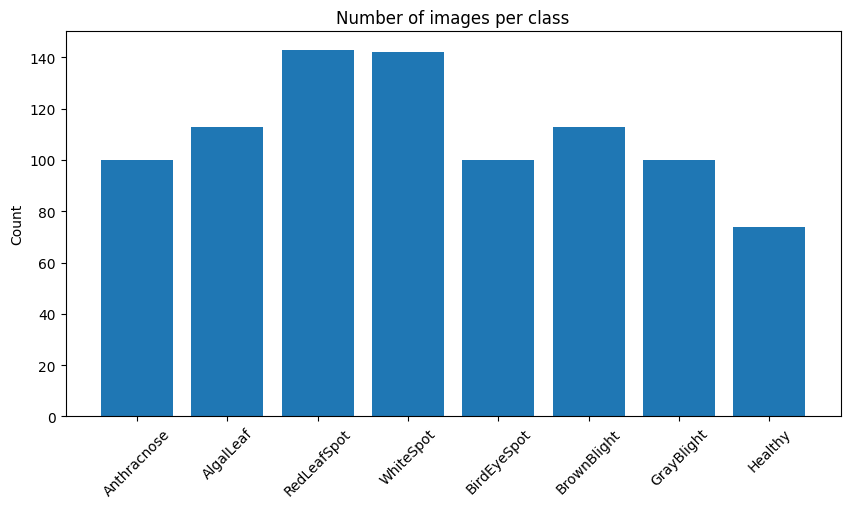

{'Anthracnose': 100,
 'AlgalLeaf': 113,
 'RedLeafSpot': 143,
 'WhiteSpot': 142,
 'BirdEyeSpot': 100,
 'BrownBlight': 113,
 'GrayBlight': 100,
 'Healthy': 74}

In [2]:

dataset_dir = "/content/drive/MyDrive/TeaDiseaseDataset"

class_counts = {}
for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

plt.figure(figsize=(10,5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.show()

class_counts


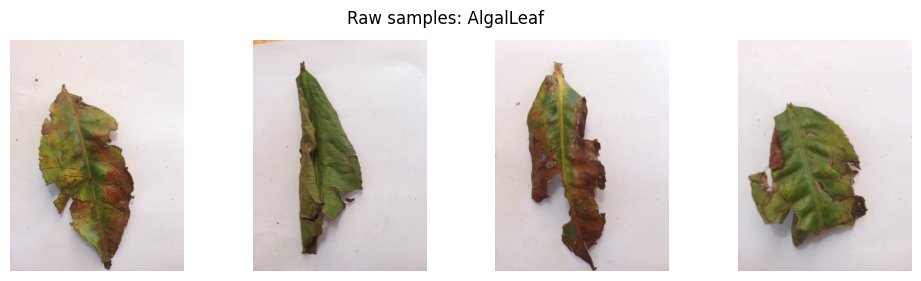

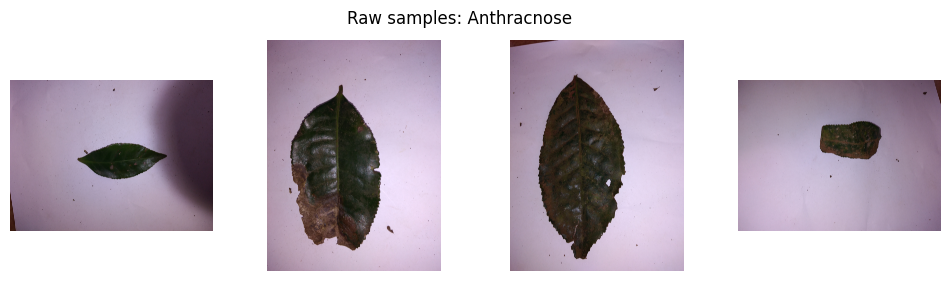

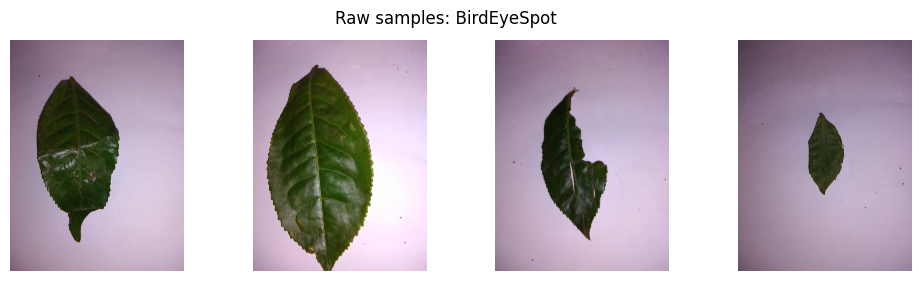

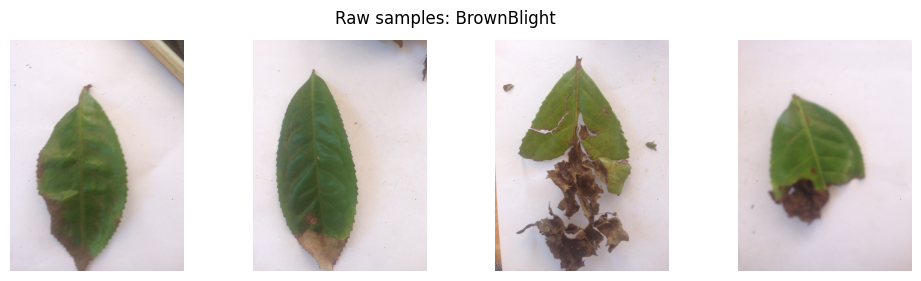

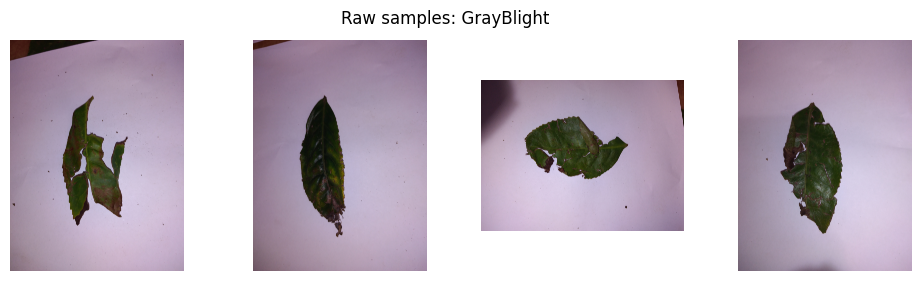

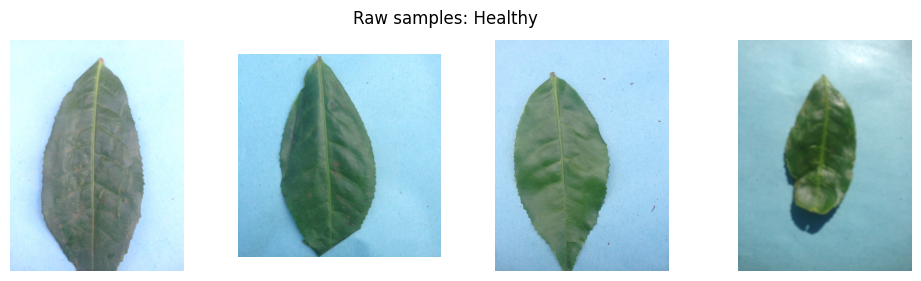

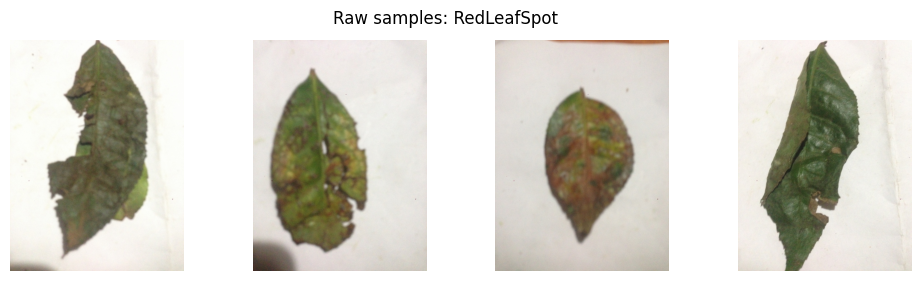

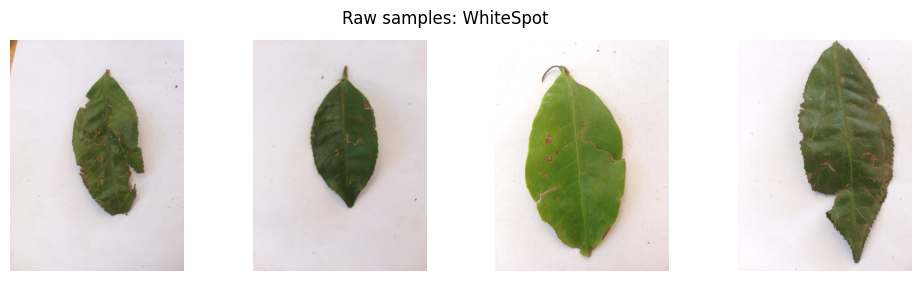

In [3]:
import random
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def show_samples_raw(dataset_dir, n=4):
    classes = sorted(os.listdir(dataset_dir))
    for cls in classes:
        cls_path = os.path.join(dataset_dir, cls)
        if not os.path.isdir(cls_path):
            continue

        imgs = random.sample(os.listdir(cls_path), n)
        plt.figure(figsize=(12,3))
        for i, img_name in enumerate(imgs):
            img_path = os.path.join(cls_path, img_name)
            img = image.load_img(img_path)
            plt.subplot(1,n,i+1)
            plt.imshow(img)
            plt.axis("off")
        plt.suptitle(f"Raw samples: {cls}")
        plt.show()

show_samples_raw(dataset_dir)


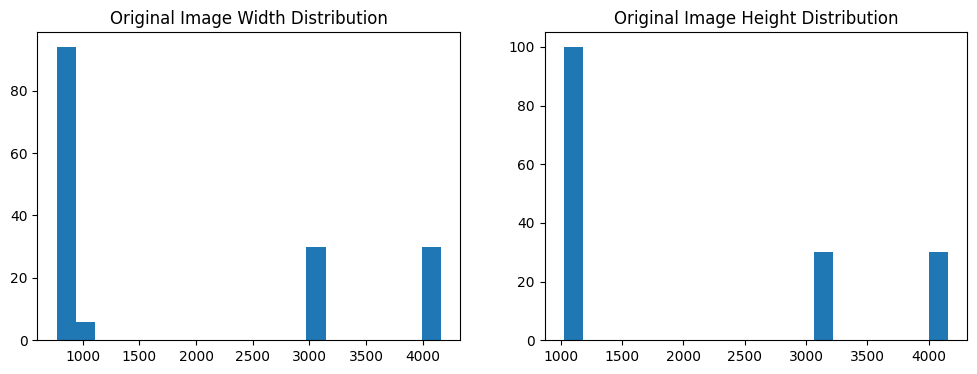

In [4]:
from PIL import Image
import random

sizes = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = random.sample(os.listdir(cls_path), min(20, len(os.listdir(cls_path))))
    for img_name in imgs:
        img_path = os.path.join(cls_path, img_name)
        with Image.open(img_path) as im:
            sizes.append(im.size)

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(widths, bins=20)
plt.title("Original Image Width Distribution")

plt.subplot(1,2,2)
plt.hist(heights, bins=20)
plt.title("Original Image Height Distribution")
plt.show()


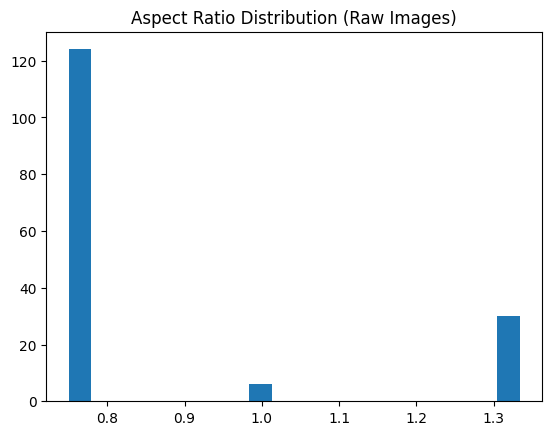

In [5]:
ratios = [w/h for w,h in sizes]

plt.hist(ratios, bins=20)
plt.title("Aspect Ratio Distribution (Raw Images)")
plt.show()


In [6]:
bad_files = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    for f in os.listdir(cls_path):
        path = os.path.join(cls_path, f)
        try:
            with Image.open(path) as im:
                im.verify()
        except:
            bad_files.append(path)

print("Corrupted images:", len(bad_files))


Corrupted images: 0


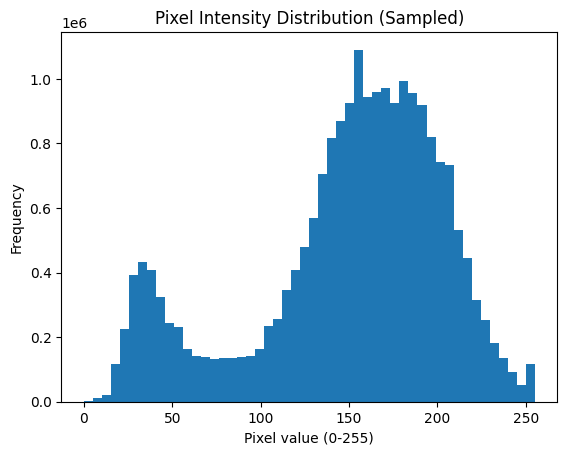

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import os

pixel_values = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = os.listdir(cls_path)

    # only sample few images per class
    sample_imgs = random.sample(imgs, min(5, len(imgs)))

    for img_name in sample_imgs:
        img_path = os.path.join(cls_path, img_name)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            # sample pixels instead of all pixels
            pixel_values.extend(img.flatten()[::10])

plt.hist(pixel_values, bins=50)
plt.title("Pixel Intensity Distribution (Sampled)")
plt.xlabel("Pixel value (0-255)")
plt.ylabel("Frequency")
plt.show()


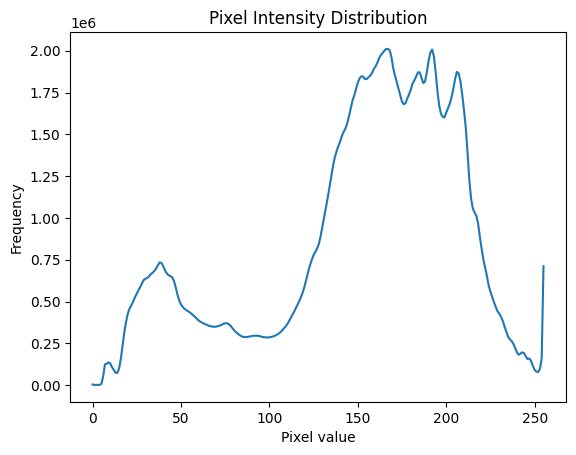

In [8]:
hist_total = np.zeros(256)

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = random.sample(os.listdir(cls_path), 5)

    for img_name in imgs:
        img = cv2.imread(os.path.join(cls_path, img_name), 0)
        hist = cv2.calcHist([img],[0],None,[256],[0,256])
        hist_total += hist.flatten()

plt.plot(hist_total)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()


Pre-processing


In [9]:

base_output = "/content/drive/MyDrive/TeaDataset_Split"
train_dir = os.path.join(base_output, "Train")
val_dir   = os.path.join(base_output, "Valid")
test_dir  = os.path.join(base_output, "Test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

split_ratio = (0.7, 0.15, 0.15)

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    images = os.listdir(cls_path)
    random.shuffle(images)

    total = len(images)
    train_end = int(split_ratio[0] * total)
    val_end   = train_end + int(split_ratio[1] * total)

    splits = {
        train_dir: images[:train_end],
        val_dir: images[train_end:val_end],
        test_dir: images[val_end:]
    }

    for split_dir, img_list in splits.items():
        cls_split_dir = os.path.join(split_dir, cls)
        os.makedirs(cls_split_dir, exist_ok=True)

        for img in img_list:
            shutil.copy(
                os.path.join(cls_path, img),
                os.path.join(cls_split_dir, img)
            )


KeyboardInterrupt: 

In [10]:

train_dir = "/content/drive/MyDrive/TeaDataset_Split/Train"
val_dir   = "/content/drive/MyDrive/TeaDataset_Split/Valid"
test_dir  = "/content/drive/MyDrive/TeaDataset_Split/Test"


In [11]:
img_height = 224
img_width  = 224
batch_size = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    #rotation_range=20,
    #zoom_range=0.15,
    #width_shift_range=0.1,
    #height_shift_range=0.1,
    #horizontal_flip=True

    #rotation_range=30,
    #zoom_range=0.25,
    #width_shift_range=0.15,
    #height_shift_range=0.15,
    #brightness_range=[0.7, 1.3],
    #shear_range=0.15,
    #horizontal_flip=True,
    #fill_mode="nearest"

    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

num_classes = train_gen.num_classes


Found 620 images belonging to 8 classes.
Found 130 images belonging to 8 classes.
Found 137 images belonging to 8 classes.


In [12]:

# balancing imbalanced training dataset

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode="categorical"
)

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get labels from generator
classes = train_gen.classes
class_labels = np.unique(classes)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=classes
)

class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)


Found 620 images belonging to 8 classes.
Class Weights: {0: np.float64(0.9810126582278481), 1: np.float64(1.0763888888888888), 2: np.float64(1.1071428571428572), 3: np.float64(0.9810126582278481), 4: np.float64(1.1071428571428572), 5: np.float64(1.5196078431372548), 6: np.float64(0.775), 7: np.float64(0.7828282828282829)}
